In [1]:
import gc
import joblib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, make_scorer, r2_score, root_mean_squared_error

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, StandardScaler

import xgboost as xgb
from xgboost import XGBRegressor, plot_importance

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor

import re


<h2>Read-in Data</h2>

In [1]:
campd_type_dict = {
    'State': 'string',
    'Facility Name': 'string',
    'Facility ID': 'Int32',
    'Unit ID': 'string',
    'Hour': 'Int8',
    'Operating Time': 'float32',
    'Gross Load (MW)': 'float32',
    'Steam Load (1000 lb/hr)': 'float32',
    'SO2 Mass (lbs)': 'float64',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'CO2 Mass (short tons)': 'float32',
    'CO2 Mass Measure Indicator': 'string',
    'CO2 Rate (short tons/mmBtu)': 'float32',
    'CO2 Rate Measure Indicator': 'string',
    'NOx Mass (lbs)': 'float32',
    'NOx Mass Measure Indicator': 'string',
    'NOx Rate (lbs/mmBtu)': 'float32',
    'NOx Rate Measure Indicator': 'string',
    'Heat Input (mmBtu)': 'float64',
    'Heat Input Measure Indicator': 'string',
    'Primary Fuel Type': 'string',
    'Secondary Fuel Type': 'string',
    'Unit Type': 'string',
    'SO2 Controls': 'string',
    'NOx Controls': 'string',
    'Program Code': 'string',
    'Year': 'int16',
    'Source Category': 'string',
    'Latitude': 'float32',
    'Longitude': 'float32',
    'SO2 Phase': 'string',
    'NOx Phase': 'string',
    'Operating Status': 'string',
    'Max Hourly HI Rate (mmBtu/hr)': 'float32',
    'Associated Generators & Nameplate Capacity (MWe)': 'string',
    'Nameplate Capacity (MWe)': 'float32',
    'Month': 'Int8',
    'hourly_capacity_factor': 'float32',
    'hourly_ramping_factor': 'float32',
    'Nameplate Capacity (MW) - EIA': 'float32',
    'Summer Capacity (MW)': 'float32',
    'Winter Capacity (MW)': 'float32',
    'Minimum Load (MW)': 'float32',
    'Operating Year_min': 'float32',
    'Operating Year_max': 'float32',
    'Operating Year_mean': 'float32',
    'Planned Retirement Year': 'Int16',
    'unit_age_min': 'Int8',
    'unit_age_max': 'Int8',
    'unit_age_mean': 'float32',
    'Day': 'float32',
    'Temperature (F)': 'float32'
}

In [ ]:
campd_tx = pd.read_csv("TX/Hourly/Concatted File/tx_2019_2024_complete_cleaned_Full.csv", dtype=campd_type_dict)
campd_tx["Date"] = pd.to_datetime(campd_tx["Date"])
campd_tx["datetime"] = pd.to_datetime(campd_tx["datetime"])

<h2>Preprocessing Methods</h2>

In [ ]:
# manually create lag columns
def create_lag_features_per_group(group, emission_type):
    group["lag_1_hour"] = group[emission_type].shift(1)  # 1 hour lag
    group["lag_2_hours"] = group[emission_type].shift(2)  # 2 hours lag
    group["lag_1_day"] = group[emission_type].shift(24)  # 1 day lag (24 hours)
    group["lag_2_days"] = group[emission_type].shift(48)  # 2 days lag (48 hours)
    group["lag_1_week"] = group[emission_type].shift(24 * 7)  # 1 week lag (168 hours)
    group["lag_1_month"] = group[emission_type].shift(24 * 30)  # ~1 month lag (720 hours)
    group["lag_1_year"] = group[emission_type].shift(24 * 365)  # ~1 year lag (8760 hours)
    return group

def preprocess_lag_features(df, previous_year_df, emission_type):
    cutoff_year = df["Year"].min()

    # add the previous year temporarily to get lags for the first year
    df = pd.concat([df, previous_year_df])

    df = df.set_index("datetime")

    df = df.sort_index()
    df = df.sort_values(by=["Facility ID", "Unit ID", "datetime"])

    # apply the lag feature function to each group
    df = df.groupby(["Facility ID", "Unit ID"], group_keys=False).apply(
    create_lag_features_per_group, emission_type=emission_type)

    df = df.reset_index()

    # filter out the previous year again
    df = df[df["Year"] >= cutoff_year]

    # ensure to add datetime back as normal column
    df["datetime"] = pd.to_datetime({
    'year': df["Date"].dt.year,
    'month': df["Date"].dt.month,
    'day': df["Date"].dt.day,
    'hour': df["Hour"]
    })


    return df


In [4]:
# manually one-hot encode NOx Controls
def split_outside_parentheses(s):
    parts = []
    current = []
    depth = 0  # track parentheses depth

    for char in s:
        if char == '(':
            depth += 1
        elif char == ')':
            depth = max(depth - 1, 0)
        
        # Split on ',' or '|' only if outside parentheses
        if (char == ',' or char == '|') and depth == 0:
            part = ''.join(current).strip()
            if part:
                parts.append(part)
            current = []
        else:
            current.append(char)
    
    # Append last part
    part = ''.join(current).strip()
    if part:
        parts.append(part)
    
    return parts

# function for one-hot encoding NOx Controls
def preprocess_nox_controls(df):
    df = df.copy()
    df = df.dropna(subset=['NOx Controls'])
    
    # apply custom splitting
    control_lists = df['NOx Controls'].apply(split_outside_parentheses)
    
    # One-hot encode controls
    mlb = MultiLabelBinarizer()
    control_matrix = mlb.fit_transform(control_lists)
    
    # create a df from the binary matrix
    controls_df = pd.DataFrame(control_matrix, columns=mlb.classes_, index=df.index)
    
    df = df.drop(columns=['NOx Controls'])
    df = pd.concat([df, controls_df], axis=1)
    
    return df, mlb.classes_  # return control column names for later use

# campd_tx, tx_control_cols = preprocess_nox_controls(campd_tx)
# tx_control_cols

In [5]:
# manually one-hot encode Program Codes
def preprocess_program_codes(df):

    # split the strings into lists
    program_lists = df['Program Code'].str.split(', ')

    mlb = MultiLabelBinarizer()
    program_dummies = pd.DataFrame(mlb.fit_transform(program_lists), 
                                columns=mlb.classes_, 
                                index=df.index)

    # concatenate with original DataFrame or add to your features
    df = pd.concat([df, program_dummies], axis=1)

    return df, mlb.classes_


# campd_tx, tx_code_cols = preprocess_program_codes(campd_tx)
# tx_code_cols

In [ ]:
# adjust the immense number of changed unit types that are indicated by e. g. "(Started Dec 12, 2022)"
def parse_unit_type(unit_str, ref_date):

    parts = re.split(r',\s*(?![^()]*\))', unit_str) # split only on commas outside parentheses
    active_units = []

    for part in parts:
        match = re.match(r"^(.*?)\s*\(\s*(Started|Ended)\s+([A-Za-z]+ \d{1,2}, \d{4})\s*\)$", part.strip())
        if match:
            unit, action, date_str = match.groups()

            event_date = pd.to_datetime(date_str)

            if action == "Started" and event_date <= ref_date:
                active_units.append(unit.strip())
            elif action == "Ended" and event_date > ref_date:
                active_units.append(unit.strip())
        else:
            active_units.append(part.strip())

    return ", ".join(active_units) if active_units else "Nothing"

<h2>Model-independent Preprocessing</h2>

- create time-lags
- manually OHE NOx controls and program codes
- downsample the non-operating rows by 90%
- remove rows where NOx was not fully measured
- adjust unit type entries where dates were added to the string to indicate a start/end date

In [ ]:
# read in previous year to get according lags
campd_tx_2018 = pd.read_csv("TX/Hourly/Before 2019/emissions-hourly-2018-tx.csv", dtype=campd_type_dict, parse_dates=["Date"])
campd_tx_2018 = campd_tx_2018[["Facility ID", "Unit ID", "Date", "Hour", "NOx Mass (lbs)"]]
campd_tx_2018["datetime"] = pd.to_datetime({
    'year': campd_tx_2018["Date"].dt.year,
    'month': campd_tx_2018["Date"].dt.month,
    'day': campd_tx_2018["Date"].dt.day,
    'hour': campd_tx_2018["Hour"]
    })
campd_tx_2018["NOx Mass (lbs)"] = campd_tx_2018["NOx Mass (lbs)"].fillna(0)

# compute lags
campd_df = preprocess_lag_features(campd_tx, campd_tx_2018, "NOx Mass (lbs)")

In [ ]:
campd_df.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_with_NOx_lags.csv", index=False)

In [ ]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_with_NOx_lags.csv", dtype=campd_type_dict)
campd_df["Date"] = pd.to_datetime(campd_df["Date"])
campd_df["datetime"] = pd.to_datetime(campd_df["datetime"])

In [ ]:
# manually one-hot encode nox controls and program codes
campd_df, df_control_cols = preprocess_nox_controls(campd_df)
campd_df, df_code_cols = preprocess_program_codes(campd_df)

# manually sin/cos encode cyclical features hour, day, month
def encode_cyclical(df, col, max_val):
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / max_val)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / max_val)
    col_names = [f"{col}_sin", f"{col}_cos"]
    return df, col_names
campd_df, hour_cols = encode_cyclical(campd_df, "Hour", 24) # Daily seasonality
campd_df, day_cols = encode_cyclical(campd_df, "Day", 7)  # Weekly seasonality
campd_df, month_cols = encode_cyclical(campd_df, "Month", 12) # Yearly seasonality
cyclical_cols = hour_cols + day_cols + month_cols

In [ ]:
campd_df.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded.csv", index=False)

In [ ]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded.csv", dtype=campd_type_dict)

In [ ]:
# Randomly remove a fraction of rows where Operating Time is 0.
def downsample_zero_operating_time(df, frac_to_remove=0.9, random_state=42):
    # create dfs for those with and without operating time
    zero_op = df[df["Operating Time"] == 0]
    non_zero_op = df[df["Operating Time"] != 0]

    # remove sample of rows
    drop_sample = zero_op.sample(frac=frac_to_remove, random_state=random_state)
    kept_zero_op = zero_op.drop(index=drop_sample.index)
    df_downsampled = pd.concat([non_zero_op, kept_zero_op]).sort_index()

    return df_downsampled


In [ ]:
# Downsample 90% of the nonOperating data (should be fine since xgb does not require continuity unlike e. g. LSTM)
campd_df = downsample_zero_operating_time(campd_df)

In [ ]:
campd_df.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled.csv", index=False)

In [ ]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.csv", dtype=campd_type_dict)

In [ ]:
campd_df = campd_df[(campd_df["NOx Mass Measure Indicator"] == "Measured") | (campd_df["NOx Mass Measure Indicator"] == "Nothing")]
campd_df["NOx Mass Measure Indicator"].value_counts()

NOx Mass Measure Indicator
Measured    8615784
Nothing     1142922
Name: count, dtype: Int64

In [ ]:
campd_df.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", index=False, compression="gzip")

In [3]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [ ]:
# adjust time-dependent unit type entries (especially important to avoid ohe adding lots of unnecessary columns)
cols_to_adjust = ['Combustion turbine (Started Jul 01, 2024), Combined cycle (Ended Jul 01, 2024)',
                    'Combustion turbine (Started Jun 12, 2024), Combined cycle (Ended Jun 12, 2024)',
                                      'Combustion turbine (Started Dec 29, 2022)',
                                      'Combustion turbine (Started Jan 24, 2023)',
                                      'Combustion turbine (Started Nov 15, 2021)',
                                          'Combined cycle (Started Aug 30, 2020)',
                                          'Combined cycle (Started Sep 04, 2020)',
                                      'Combustion turbine (Started Mar 25, 2019)',
                                      'Combustion turbine (Started Apr 02, 2019)',
                                      'Combustion turbine (Started May 26, 2022)',
                                      'Combustion turbine (Started May 25, 2022)',
                                      'Combustion turbine (Started Sep 01, 2021)',
                                      'Combustion turbine (Started Jul 05, 2021)',
                                      'Combustion turbine (Started Aug 04, 2021)',
                                      'Combustion turbine (Started Jul 08, 2021)',
                                      'Combustion turbine (Started Jul 12, 2021)',
                                      'Combustion turbine (Started Sep 09, 2021)',
                                      'Combustion turbine (Started Aug 22, 2022)',
                                      'Combustion turbine (Started Jun 26, 2022)',
                                      'Combustion turbine (Started Mar 30, 2022)',
                                      'Combustion turbine (Started Mar 29, 2022)',
                                      'Combustion turbine (Started Mar 22, 2022)',
                                      'Combustion turbine (Started Mar 14, 2022)',
                                      'Combustion turbine (Started Mar 11, 2022)',
                                      'Combustion turbine (Started Mar 10, 2022)',
                                      'Combustion turbine (Started Sep 26, 2022)',
                                      'Combustion turbine (Started Sep 27, 2022)',
                                      'Combustion turbine (Started Sep 30, 2022)',
                                      'Combustion turbine (Started Oct 16, 2024)',
                                      'Combustion turbine (Started May 05, 2023)',
                                      'Combustion turbine (Started Apr 13, 2023)',
                                      'Combustion turbine (Started Apr 12, 2023)',
                                      'Combustion turbine (Started Apr 03, 2023)',
                                      'Combustion turbine (Started Mar 17, 2023)',
                                      'Combustion turbine (Started Mar 16, 2023)',
                                      'Combustion turbine (Started Jul 17, 2023)',
                                      'Combustion turbine (Started Aug 02, 2023)',
                                      'Combustion turbine (Started May 20, 2024)',
                                      'Combustion turbine (Started May 23, 2024)',
                                      'Combustion turbine (Started May 22, 2024)',
                                      'Combustion turbine (Started Aug 09, 2024)']

campd_df_to_adjust = campd_df[campd_df["Unit Type"].isin(cols_to_adjust)].copy()

campd_df_to_adjust["Unit Type"] = campd_df_to_adjust.apply(
    lambda row: parse_unit_type(row["Unit Type"], pd.to_datetime(row["datetime"])), axis=1
)

campd_df = pd.concat([
    campd_df[~(campd_df["Unit Type"].isin(cols_to_adjust))],       
    campd_df_to_adjust    
])

In [ ]:
campd_df["Unit Type"].unique()

<StringArray>
[                  'Combined cycle',     'Dry bottom wall-fired boiler',
               'Combustion turbine',               'Tangentially-fired',
 'Circulating fluidized bed boiler',                          'Nothing',
    'Bubbling fluidized bed boiler']
Length: 7, dtype: string

In [ ]:
campd_df.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", index=False, compression="gzip")

In [3]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)
campd_df.shape

(9758706, 92)

<h2>Regression Models</h2>

- for each model type, we preprocess data appropriately and evaluate models with default parameters using 2019-2023 training data and 2024 as the test data
-> prepare models for xAI analysis

<h3>Random Forest</h3>

- build RF models using sklearn default parameters without and with lags
- this version of RF handles null values inherently so we do not need to impute/remove them
- to keep training computationally feasible, we downsample the training data to 20%
- lastly, we conduct a rudimentary scenario analysis to simulate an SCR adaption across all units in 2024

In [ ]:
# default params are:
# n_estimators=100, *, criterion='gini', max_depth=None, min_samples_split=2, 
# min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', 
# max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False,
#  n_jobs=None, random_state=None, verbose=0, warm_start=False, class_weight=None, 
# ccp_alpha=0.0, max_samples=None, monotonic_cst=None

In [ ]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners', 'Dry Low NOx Burners (Began Aug 03, 2022)',
       'Dry Low NOx Burners (Began Jul 01, 2024)',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Steam Injection (Retired Aug 02, 2022)',
       'Steam Injection (Retired Jun 30, 2024)', 'Water Injection']
df_code_cols = ['ARP',
       'CSOSG2', 'MATS', 'Missing', 'TXSO2']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] + lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [ ]:
# rf struggles with large datasets, so we downsample the training data to 20%
# Sample while keeping the original time order (just doing .sample() shuffles order)
sample_indices = X_train.sample(frac=0.2, random_state=42).index
X_sampled = X_train.loc[X_train.index.isin(sample_indices)]
y_sampled = y_train.loc[y_train.index.isin(sample_indices)]

In [9]:
X_sampled.shape

(1607705, 131)

<h4>No Lags</h4>

In [ ]:
# still takes approx. 12 mins to compute

rf_model_no_lags = RandomForestRegressor(random_state=42, n_jobs=-1) 

# Train Random Forest model with default parameters
rf_model_no_lags.fit(X_sampled, y_sampled.values.ravel())

RandomForestRegressor(n_jobs=-1, random_state=42)

In [11]:
joblib.dump(rf_model_no_lags, "TX/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_tx_no_lags_no_unmeasured_with_temps.json", compress=True)

['TX/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_tx_no_lags_no_unmeasured_with_temps.json']

In [6]:
rf_model_no_lags = joblib.load("TX/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_tx_no_lags_no_unmeasured_with_temps.json")

R^2 Score: 0.9510
Mean Squared Error (MSE): 2065.5086
Root Mean Squared Error (RMSE): 45.4479
Normalized RMSE (by std): 0.2215


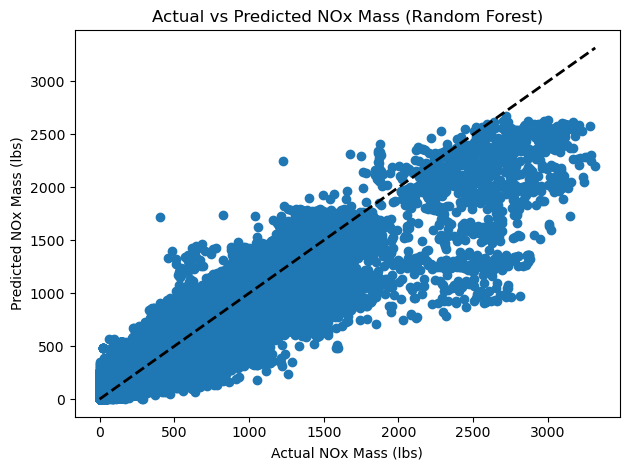

In [12]:
# default model (no lags, no unmeasured data, with temps)

y_pred = rf_model_no_lags.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

<h4>With Lags</h4>

In [ ]:
# still takes approx. 10 mins to compute

rf_model_with_lags = RandomForestRegressor(random_state=42, n_jobs=-1)

rf_model_with_lags.fit(X_sampled, y_sampled.values.ravel())

RandomForestRegressor(n_jobs=-1, random_state=42)

In [19]:
joblib.dump(rf_model_with_lags, "TX/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_tx_with_lags_no_unmeasured_with_temps.json", compress=True)

['TX/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_tx_with_lags_no_unmeasured_with_temps.json']

In [ ]:
rf_model_with_lags = joblib.load("TX/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_tx_with_lags_with_unmeasured_with_temps.json")

R^2 Score: 0.9848
Mean Squared Error (MSE): 639.2601
Root Mean Squared Error (RMSE): 25.2836
Normalized RMSE (by std): 0.1232


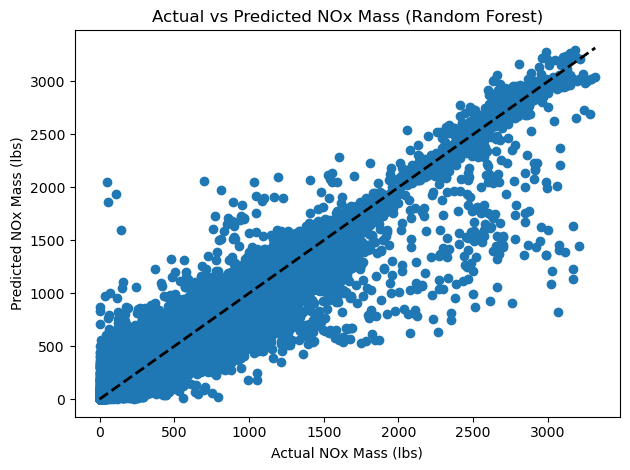

In [20]:
# default model (with lags, no unmeasured data, with temps)

y_pred = rf_model_with_lags.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

<h4>Scenario Analysis</h4>

In [ ]:
# use the default model with no lags, no unmeasured data, with temps to compare
y_pred_real = y_pred # prediction from model with real X_test

y_pred_sum = sum(y_pred_real)
y_test_sum = sum(y_test.values)[0]

print(f"Total Predicted NOx Mass (lbs): {y_pred_sum:.4f}")
print(f"Total Actual NOx Mass (lbs): {y_test_sum:.4f}")
print(f"Relative Difference: {(y_pred_sum - y_test_sum) / y_test_sum:.4%}")
print(f"Total Difference: {y_pred_sum - y_test_sum:.4f}")

# the original model miscalculates actual NOx sum by 1.21% which is reasonably low in relative terms
# about 1,952,759 lbs off in absolute terms

Total Predicted NOx Mass (lbs): 159122698.9672
Total Actual NOx Mass (lbs): 161075458.7380
Relative Difference: -1.2123%
Total Difference: -1952759.7708


In [24]:
# simulate all units having SCR in X_test (2024) and look at difference to prediction using real data
X_test_all_SCR = X_test
X_test_all_SCR["encoded__Selective Catalytic Reduction"] = 1

# model with default parameters (no lags, no unmeasured data, with temps)

# predict on data with all SCR = 1

y_pred_all_scr = rf_model_no_lags.predict(X_test_all_SCR)

# set all predictions below 0 to 0
y_pred_all_scr[y_pred_all_scr < 0] = 0

In [25]:
# Difference between real prediction and prediction with all SCR
print(f"Relative Difference: {(y_pred_real.sum() - y_pred_all_scr.sum()) / y_pred_real.sum():.4%}")
print(f"Total Difference: {y_pred_real.sum() - y_pred_all_scr.sum():.4f}")

Relative Difference: 44.6923%
Total Difference: 71115581.4632


In [ ]:
# only about 50% of the entries in X_test had SCR
X_test["encoded__Selective Catalytic Reduction"].sum() / len(X_test)

0.516150635398621

<h3>XGBoost</h3>

<h5>Preprocessing</h5>

In [ ]:
campd_df = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [4]:
df_control_cols = ['Ammonia Injection',
       'Combustion Modification/Fuel Reburning', 'Dry Low NOx Burners',
       'Dry Low NOx Burners (Began Aug 03, 2022)',
       'Dry Low NOx Burners (Began Jul 01, 2024)',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Steam Injection (Retired Aug 02, 2022)',
       'Steam Injection (Retired Jun 30, 2024)', 'Water Injection']
df_code_cols = ['ARP',
       'CSOSG2', 'MATS', 'Missing', 'TXSO2']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

In [ ]:
# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 
                'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] + lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan


ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Month', 'Hour', 'Day', 'Source Category',
                                  'NOx Phase', 'Unit Type', 'Primary Fuel Type',
                                  'Secondary Fuel Type']),
                                ('num', 'passthrough',
                                 ['Gross Load (MW)', 'Heat Input (mmBtu)',
                                  'Latitude', 'Longitude',
                                  'Nameplate Capacity (MWe)',
                                  'hourly_capacity_factor',
                                  'hourly_ramping_facto...
                                  'Closed-coupled/Separated OFA',
                                  'Low NOx Burner Technology w/ Overfire Air',
                                  'Low NOx Burner Technology w/ Separated OFA',
                                  'Nothing', 'Other', 'Overfire Air',
                                  'Selective Catalytic Reduction',
                                  'Selective Non-catalytic Reduction',
                                  'Steam Injection',
                                  'Steam Injection (Retired Aug 02, 2022)',
                                  'Steam Injection (Retired Jun 30, 2024)',
                                  'Water Injection', 'ARP', 'CSOSG2', 'MATS',
                                  'Missing', 'TXSO2'])])

In [ ]:
X_train.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/X_train.gz", index=False, compression="gzip")
X_test.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/X_test.gz", index=False, compression="gzip")
y_train.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/y_train.gz", index=False, compression="gzip")
y_test.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/y_test.gz", index=False, compression="gzip")

In [ ]:
X_train = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/X_train.gz", dtype=campd_type_dict)
X_test = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/X_test.gz", dtype=campd_type_dict)

In [ ]:
y_train = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/y_train.gz")
y_test = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/y_test.gz")

In [ ]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [ ]:
X_train.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed.gz", index=False, compression="gzip")
X_test.to_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed.gz", index=False, compression="gzip")

In [3]:
X_train = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed.gz", dtype=campd_type_dict)
X_test = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed.gz", dtype=campd_type_dict)

In [4]:
encoded_lag_cols = [
    "encoded__lag_1_hour",
    "encoded__lag_2_hours",
    "encoded__lag_1_day",
    "encoded__lag_2_days",
    "encoded__lag_1_week",
    "encoded__lag_1_month",
    "encoded__lag_1_year"
       ]

encoded_program_code_cols = ['encoded__ARP',
       'encoded__CSOSG2', 'encoded__MATS', 'encoded__Missing', 'encoded__TXSO2']
encoded_nox_phase_cols = ["cat__NOx Phase_Early Election", "cat__NOx Phase_Nothing"]

In [ ]:
X_train_adjusted = X_train.drop(columns=encoded_lag_cols)
X_train_adjusted = X_train_adjusted.drop(columns=encoded_program_code_cols)
X_train_adjusted = X_train_adjusted.drop(columns=encoded_nox_phase_cols)
X_train_adjusted = X_train_adjusted.drop(columns=['num__Latitude', 'num__Longitude'])

In [5]:
X_test_adjusted = X_test.drop(columns=encoded_lag_cols)
X_test_adjusted = X_test_adjusted.drop(columns=encoded_program_code_cols)
X_test_adjusted = X_test_adjusted.drop(columns=encoded_nox_phase_cols)
X_test_adjusted = X_test_adjusted.drop(columns=['num__Latitude', 'num__Longitude'])


In [8]:
dtrain_adjusted = xgb.DMatrix(X_train_adjusted, label=y_train)
dtest_adjusted = xgb.DMatrix(X_test_adjusted, label=y_test)

In [ ]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

In [24]:
dtrain.save_binary("TX/Hourly/Concatted File/Modeling/XGB/NOx/dtrain_tx_full_2019_2023.buffer")
dtest.save_binary("TX/Hourly/Concatted File/Modeling/XGB/NOx/dtest_tx_full_2024.buffer")

In [ ]:
dtrain = xgb.DMatrix("TX/Hourly/Concatted File/Modeling/XGB/NOx/dtrain_tx_full_2019_2023.buffer")
dtest = xgb.DMatrix("TX/Hourly/Concatted File/Modeling/XGB/NOx/dtest_tx_full_2024.buffer")

In [ ]:
# default parameters for comparison
default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    # "tree_method": "auto" # automatically chooses exact or approximation method based on data size

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
}

<h5>Train All, Test Year 2024</h5>

R^2 Score: 0.9532
Mean Squared Error (MSE): 1973.3765
Root Mean Squared Error (RMSE): 44.4227
Normalized RMSE (by std): 0.2163


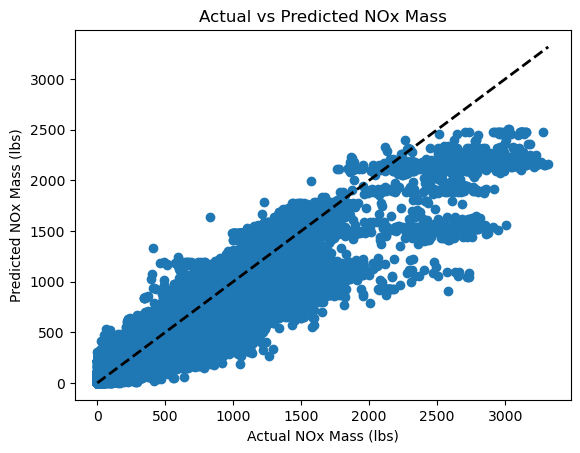

In [11]:
# model with default parameters (no lags, no unmeasured data, with temps)

# excludes columns for NOx phase, program code, AND coordinates

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain_adjusted, num_boost_round=100)

# dump model
xgb_default_model.save_model("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_tx_no_lags_no_unmeasured_with_temps_no_phase_code_coords.json")

y_pred = xgb_default_model.predict(dtest_adjusted)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_adjusted.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9536
Mean Squared Error (MSE): 1956.7382
Root Mean Squared Error (RMSE): 44.2350
Normalized RMSE (by std): 0.2154


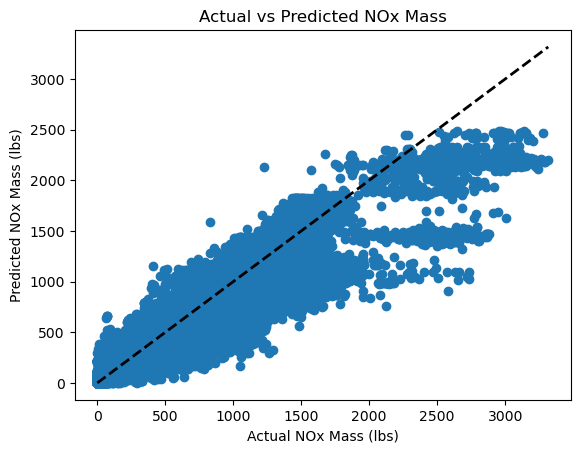

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_tx_no_lags_no_unmeasured_with_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9826
Mean Squared Error (MSE): 732.4965
Root Mean Squared Error (RMSE): 27.0647
Normalized RMSE (by std): 0.1318


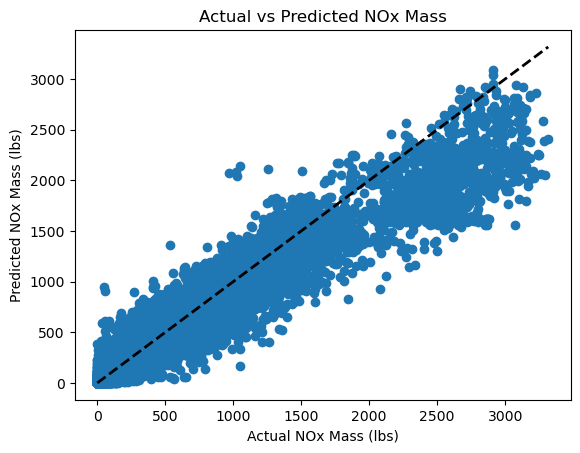

In [26]:
# model with default parameters (with lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_tx_with_lags_no_unmeasured_with_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h5>Scenario Analysis</h5>

In [42]:
# use the default model with no lags, no unmeasured data, with temps to compare
y_pred_real = y_pred # prediction from model with real X_test


In [ ]:
y_pred_sum = sum(y_pred_real)
y_test_sum = sum(y_test)

print(f"Total Predicted NOx Mass (lbs): {y_pred_sum:.4f}")
print(f"Total Actual NOx Mass (lbs): {y_test_sum:.4f}")
print(f"Relative Difference: {(y_pred_sum - y_test_sum) / y_test_sum:.4%}")
print(f"Total Difference: {y_pred_sum - y_test_sum:.4f}")

# the original model miscalculates actual NOx sum by 1.75% which is reasonably low in relative terms
# about 2,823,908 lbs off in absolute terms

Total Predicted NOx Mass (lbs): 158251549.8855
Total Actual NOx Mass (lbs): 161075458.7313
Relative Difference: -1.7532%
Total Difference: -2823908.8458


In [44]:
# simulate all units having SCR in X_test (2024) and look at difference to prediction using real data
X_test_all_SCR = X_test.copy()
X_test_all_SCR["encoded__Selective Catalytic Reduction"] = 1
dtest_all_SCR = xgb.DMatrix(X_test_all_SCR, label=y_test)

In [46]:
# predict on data with all SCR = 1

y_pred_all_scr = xgb_default_model_no_lags.predict(dtest_all_SCR)

# set all predictions below 0 to 0
y_pred_all_scr[y_pred_all_scr < 0] = 0

In [47]:
# Difference between real prediction and prediction with all SCR
print(f"Relative Difference: {(y_pred_real.sum() - y_pred_all_scr.sum()) / y_pred_real.sum():.4%}")
print(f"Total Difference: {y_pred_real.sum() - y_pred_all_scr.sum():.4f}")

Relative Difference: 41.0744%
Total Difference: 65000912.0000


<h2>Interpretability</h2>

<h5>Read-in Models</h5>

In [ ]:
# load saved models

rf_default_model_no_lags = joblib.load("TX/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_tx_no_lags_no_unmeasured_with_temps.json")

rf_default_model_with_lags = joblib.load("TX/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_tx_with_lags_no_unmeasured_with_temps.json")

xgb_default_model_with_lags = xgb.Booster()
xgb_default_model_with_lags.load_model("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_tx_with_lags_no_unmeasured_with_temps.json")

xgb_default_model_no_lags = xgb.Booster()
xgb_default_model_no_lags.load_model("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_tx_no_lags_no_unmeasured_with_temps.json")


In [6]:
xgb_default_model_no_lags_no_phase_code_coords = xgb.Booster()
xgb_default_model_no_lags_no_phase_code_coords.load_model("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_tx_no_lags_no_unmeasured_with_temps_no_phase_code_coords.json")

<h3>RF (model-specific)</h3>

- Mean Decrease in Impurity (MDI) for RF without and with lags

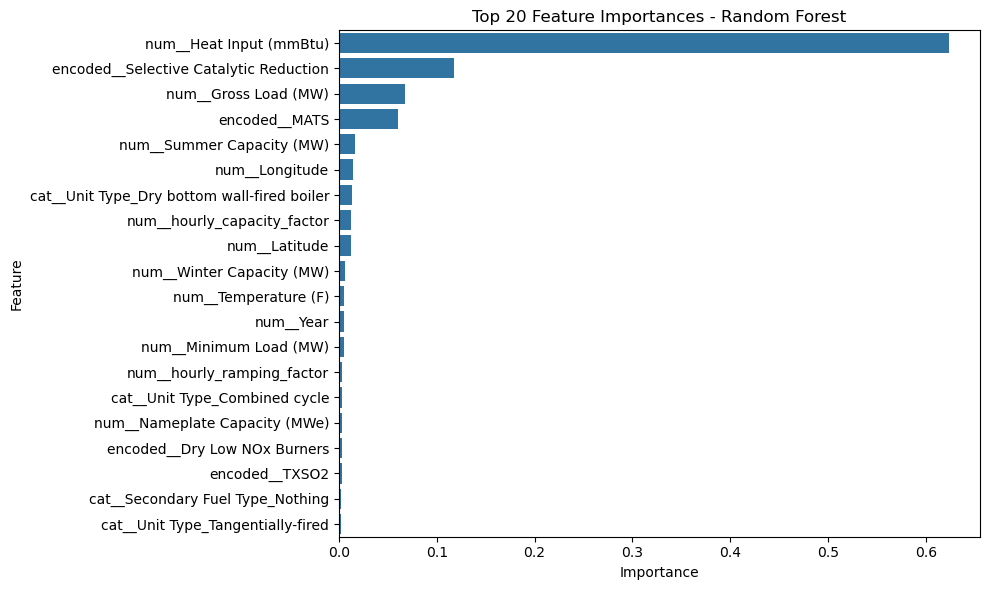

In [8]:
# for default rf model no lags, no unmeasured data, with temps

importances = rf_default_model_no_lags.feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importances
})

feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

# uses MDI (Mean Decrease in Impurity)
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(20), x='Importance', y='Feature')
plt.title('Top 20 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()


In [ ]:
# for default rf model with lags, no unmeasured data, with temps

importances = rf_default_model_with_lags.feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importances
})

feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

# uses MDI (Mean Decrease in Impurity)
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(20), x='Importance', y='Feature')
plt.title('Top 20 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()


<h3>XGB (model-specific)</h3>

- Weight, gain, and cover for XGB with and without lags (as well as for the model without lags and without select proxy variables)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

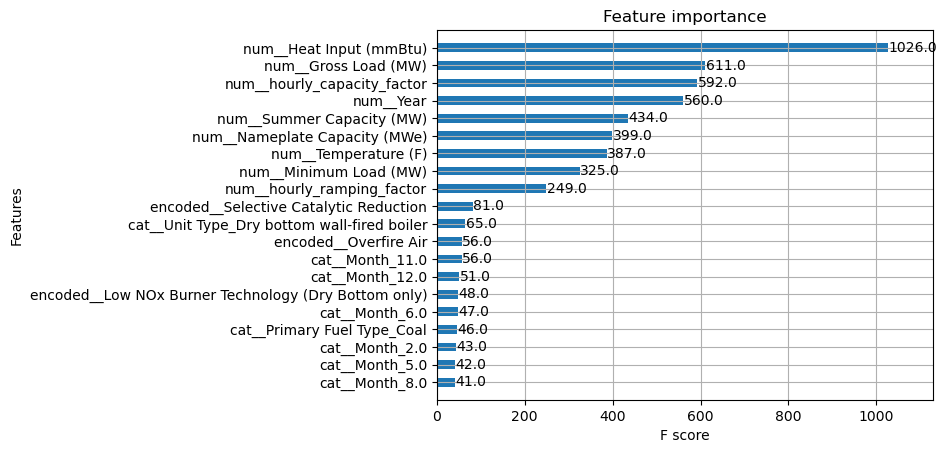

In [ ]:
# use weight for feature importance (how often the feature is used in splits)
plot_importance(
    xgb_default_model_no_lags_no_phase_code_coords, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

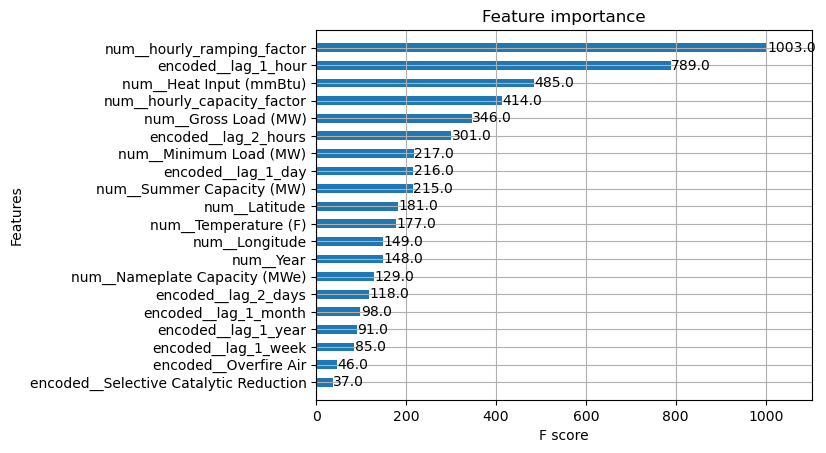

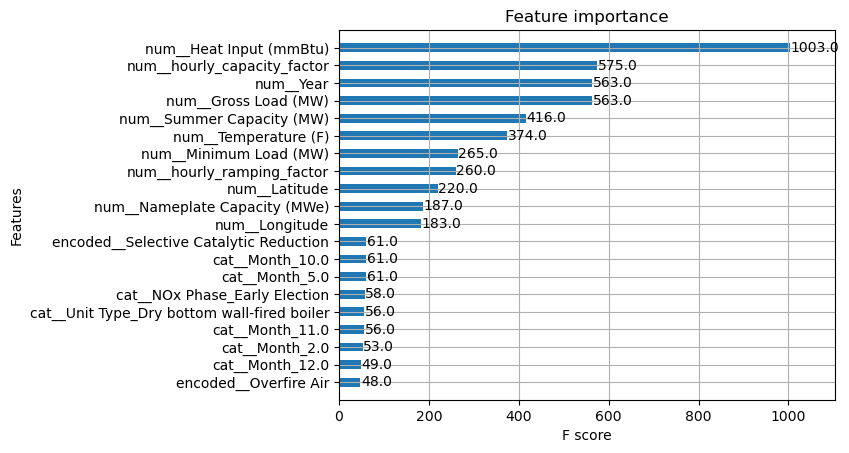

In [18]:
# use weight for feature importance (how often the feature is used in splits)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

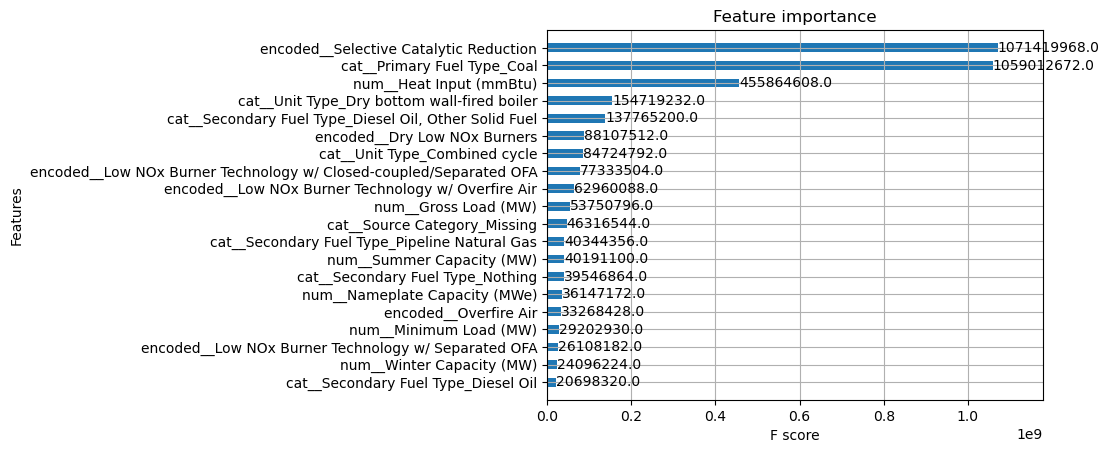

In [6]:
# use gain for feature importance (Average improvement in loss from splits involving that feature)
plot_importance(
    xgb_default_model_no_lags_no_phase_code_coords, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

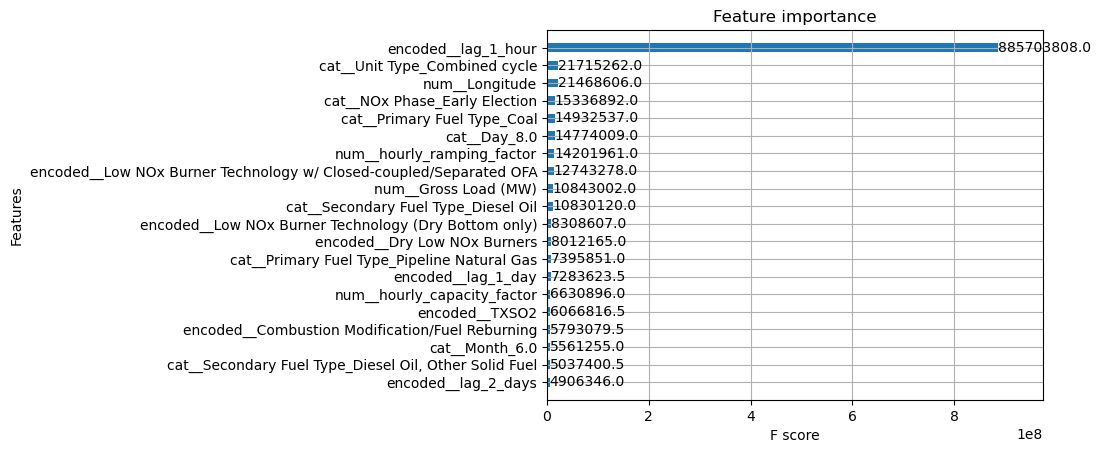

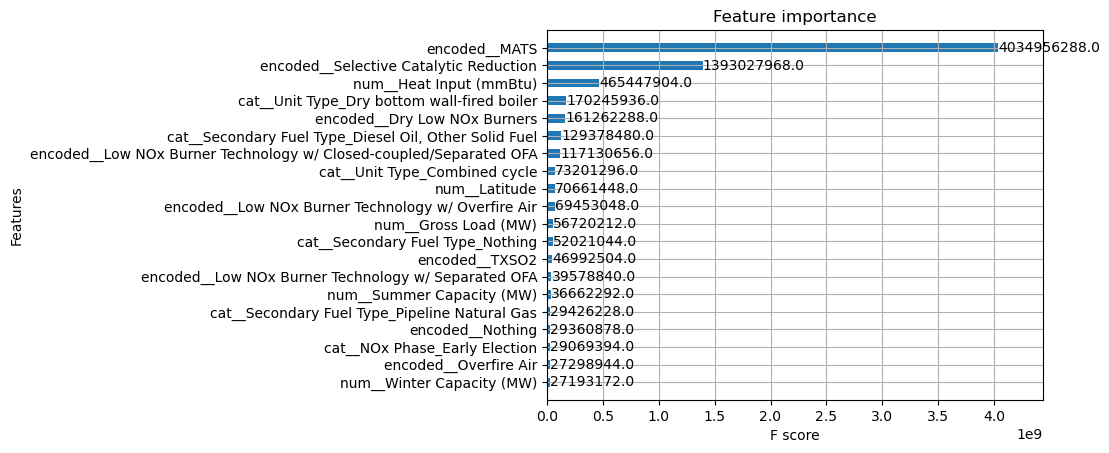

In [19]:
# use gain for feature importance (Average improvement in loss from splits involving that feature)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

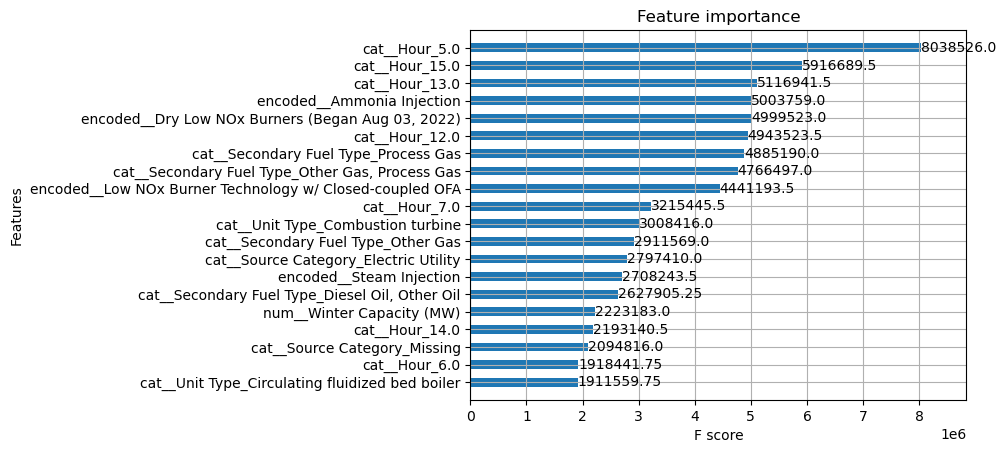

In [7]:
# use cover for feature importance (how matx observations are affected by the feature)
plot_importance(
    xgb_default_model_no_lags_no_phase_code_coords, 
    importance_type='cover',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

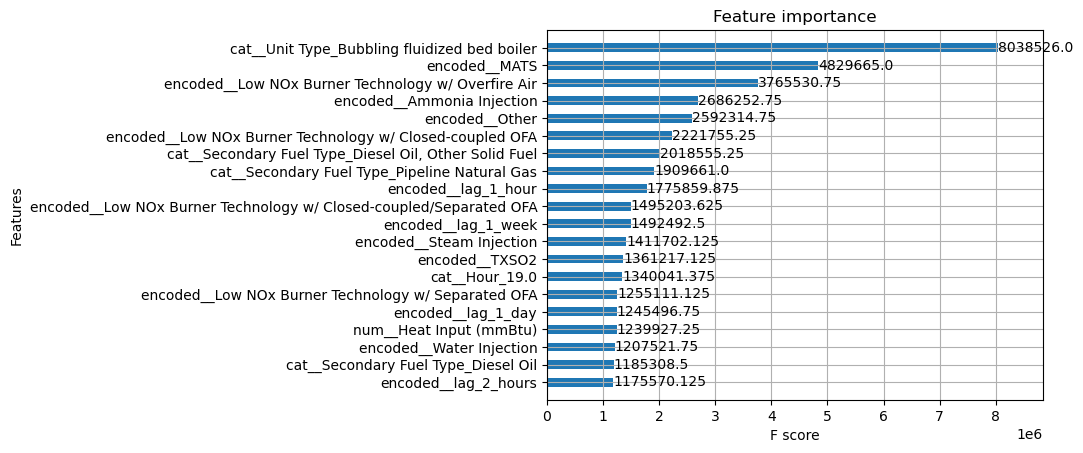

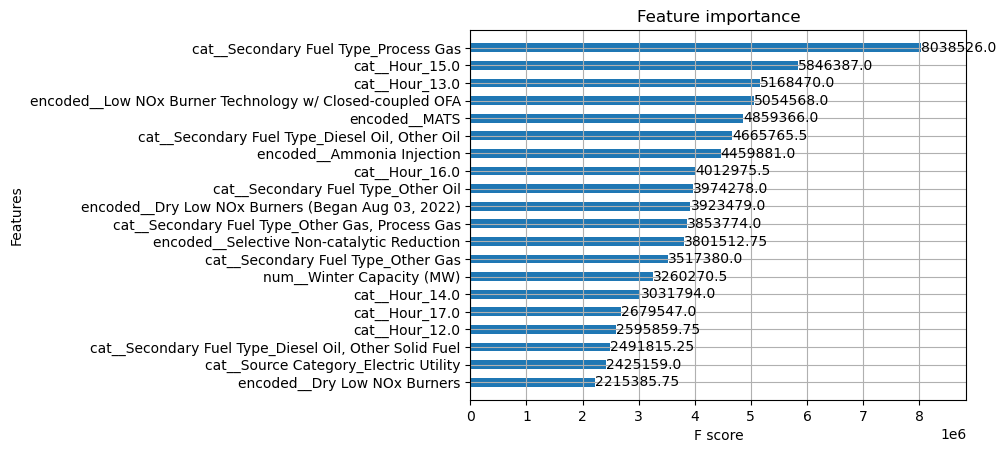

In [20]:
# use cover for feature importance (how matx observations are affected by the feature)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='cover',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='cover',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<h3>Permutation Importance</h3>

In [8]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model_no_lags_no_phase_code_coords

<h4>Ungrouped</h4>

In [ ]:
result = permutation_importance(regressor, X_test_adjusted, y_test, n_repeats=3, random_state=42, scoring='neg_mean_squared_error', n_jobs=-1)

importance_df = pd.DataFrame({
    'feature': X_test_adjusted.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

display(importance_df)

# took 12 mins


,feature,importance_mean,importance_std
94,num__Heat Input (mmBtu),60409.084603,81.705502
116,encoded__Selective Catalytic Reduction,17003.643351,24.679094
95,num__Nameplate Capacity (MWe),13401.710313,41.738102
77,cat__Primary Fuel Type_Coal,7082.210391,10.728937
93,num__Gross Load (MW),5067.891875,27.604198
...,...,...,...
45,cat__Day_10.0,-0.077071,0.087263
62,cat__Day_27.0,-0.088003,0.007455
52,cat__Day_17.0,-0.919157,0.061975
0,cat__Month_1.0,-2.674175,0.083400


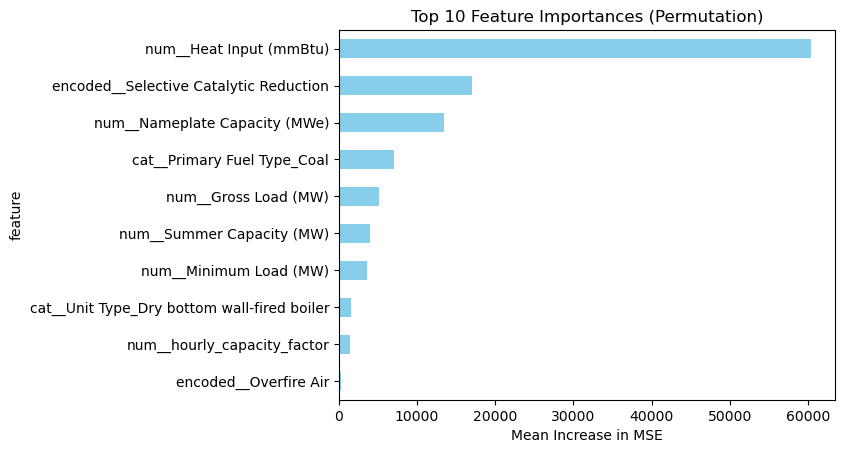

In [20]:
importance_df.head(10).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


<h3>SHAP</h3>

<h4>XGB</h4>

<h5>SHAP Values</h5>

- global aggregated SHAP values with and without lags
- exploration of SHAP value scatter plots

In [9]:
explainer = shap.TreeExplainer(xgb_default_model_no_lags)

In [ ]:
shap_values = explainer(X_test, approximate=False)

In [12]:
joblib.dump(shap_values, "TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_tx_no_lags_no_unmeasured_with_temps.pkl")

['TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_tx_no_lags_no_unmeasured_with_temps.pkl']

In [2]:
shap_values = joblib.load("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_tx_no_lags_no_unmeasured_with_temps.pkl")

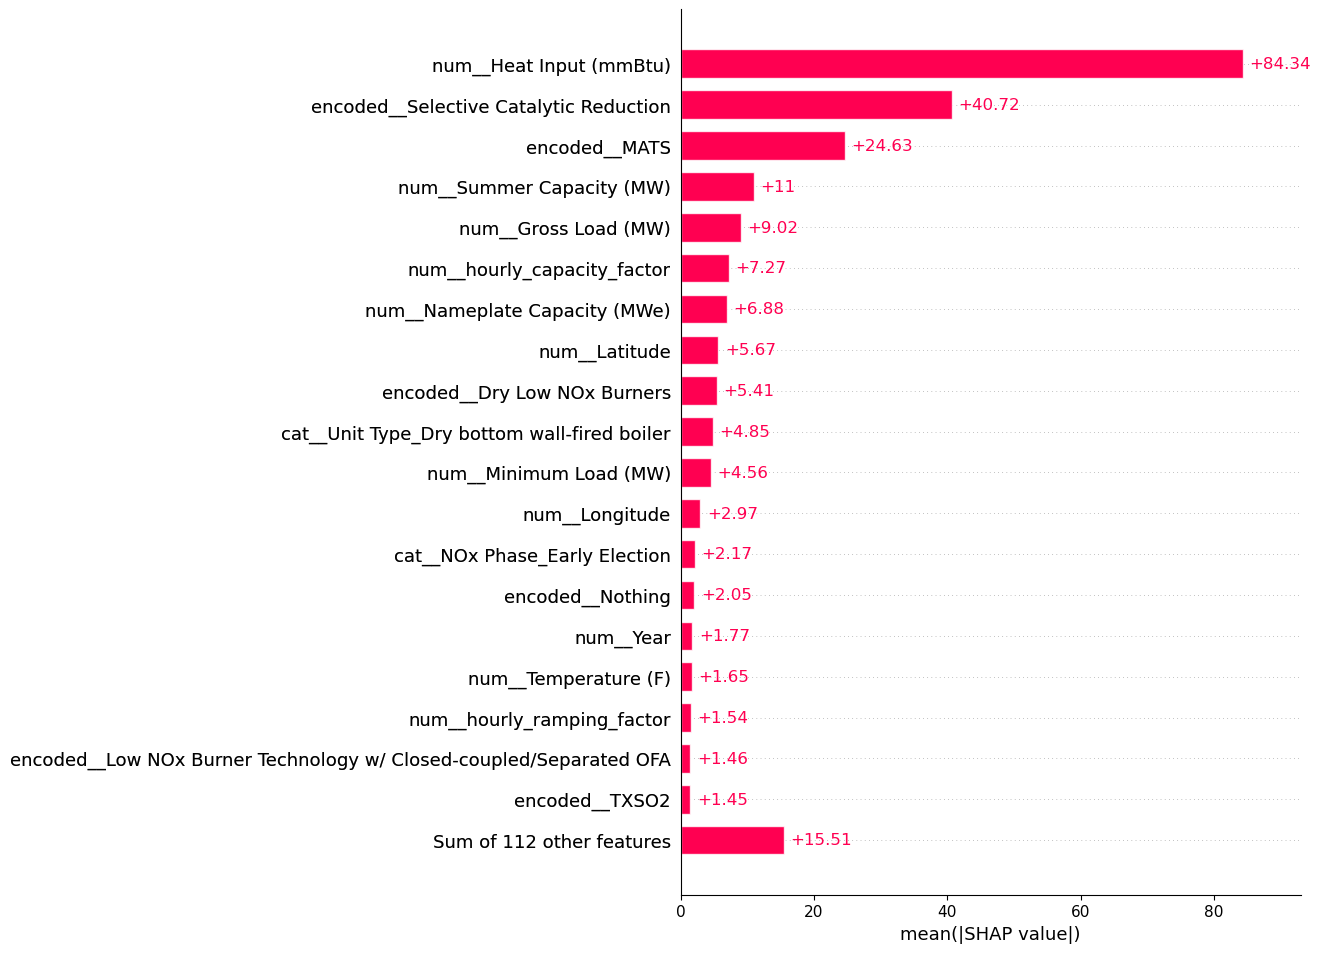

In [13]:
shap.plots.bar(shap_values, max_display=20) # global mean absolute shap values for comparison

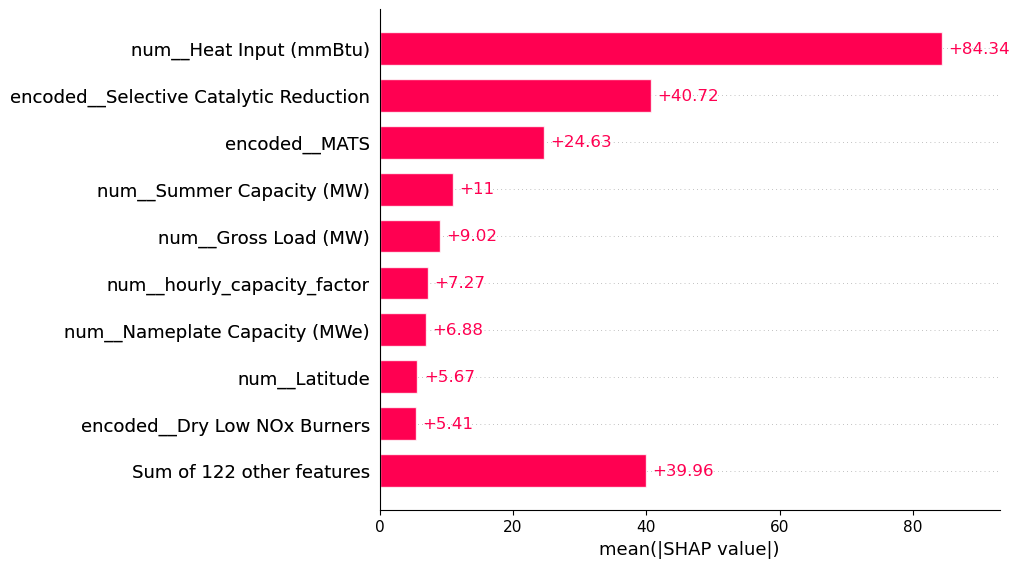

In [3]:
shap.plots.bar(shap_values, max_display=10)

In [ ]:
X_test[(X_test["encoded__MATS"] == 1)]["cat__Primary Fuel Type_Coal"].sum() / len(X_test[(X_test["encoded__MATS"] == 1)])

# MATS works as a proxy for Primary Fuel Type Coal !

1.0

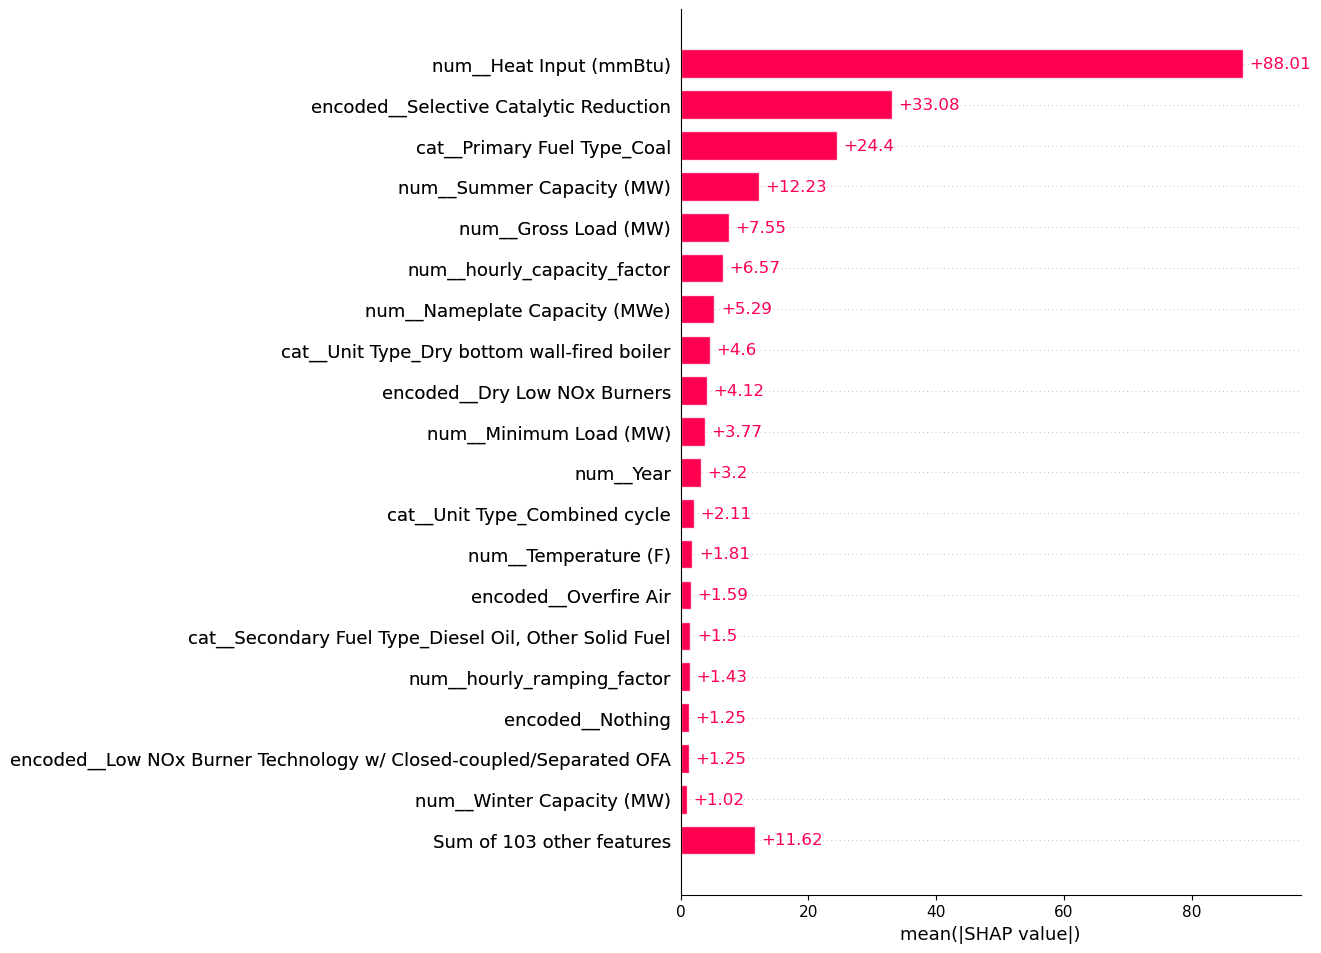

In [ ]:
# adjusted version without program codes (and without phase or coords)
explainer_adjusted = shap.TreeExplainer(xgb_default_model_no_lags_no_phase_code_coords)
shap_values_adjusted = explainer(X_test_adjusted, approximate=True)
shap.plots.bar(shap_values, max_display=20) 

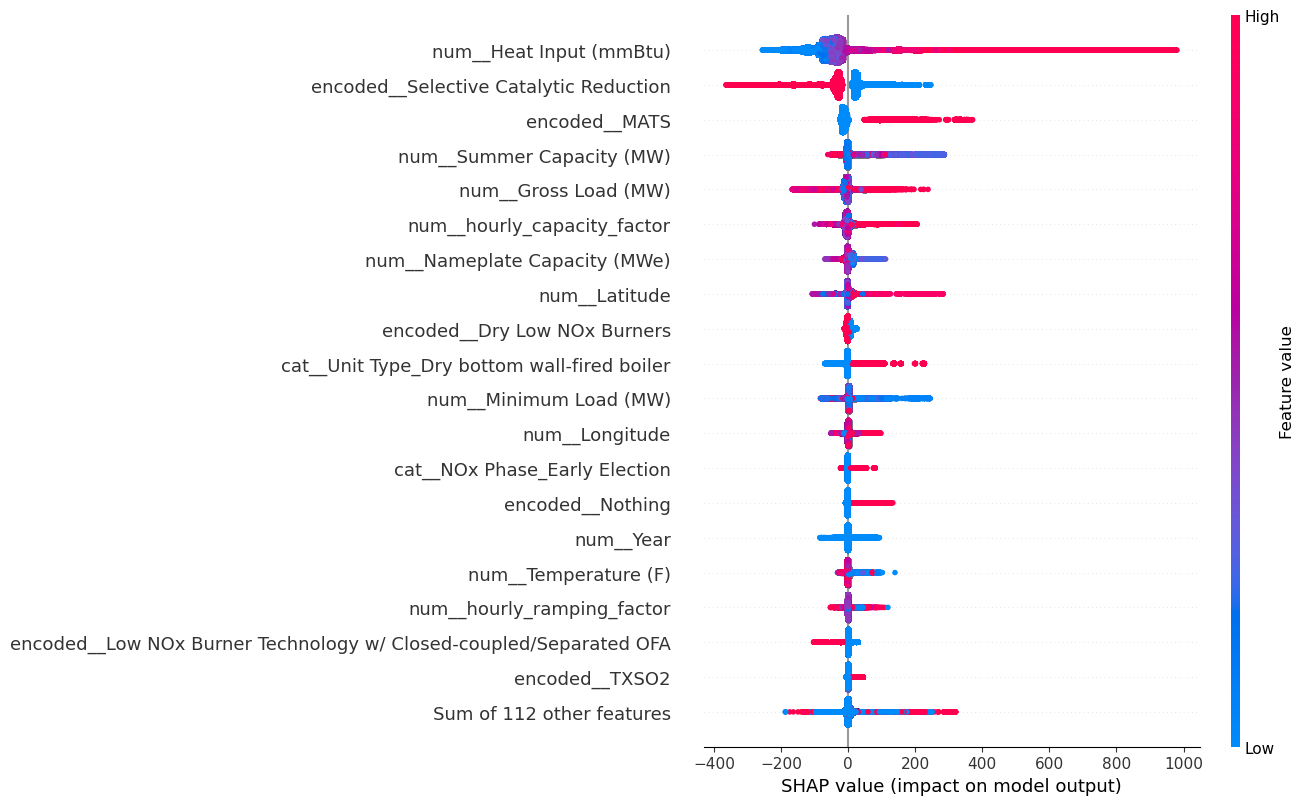

In [14]:
shap.plots.beeswarm(shap_values, max_display=20)


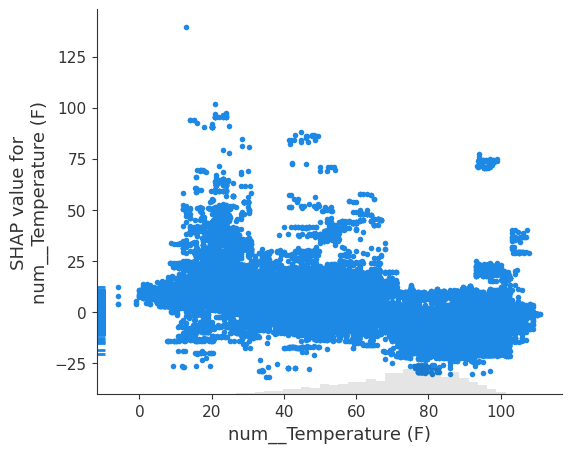

In [10]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"])

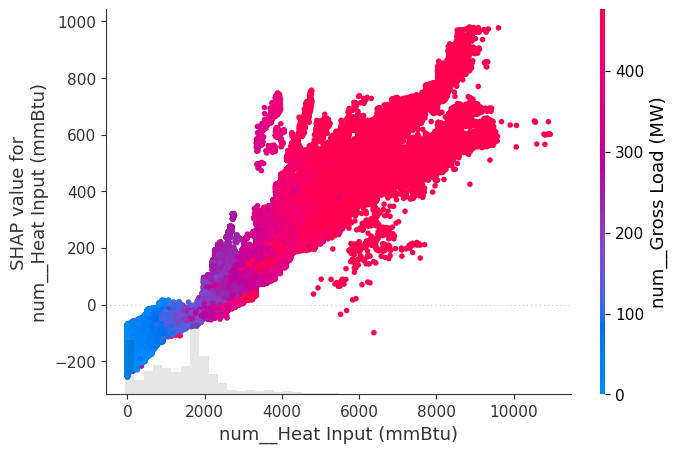

In [18]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"], color=shap_values[:,"num__Gross Load (MW)"])

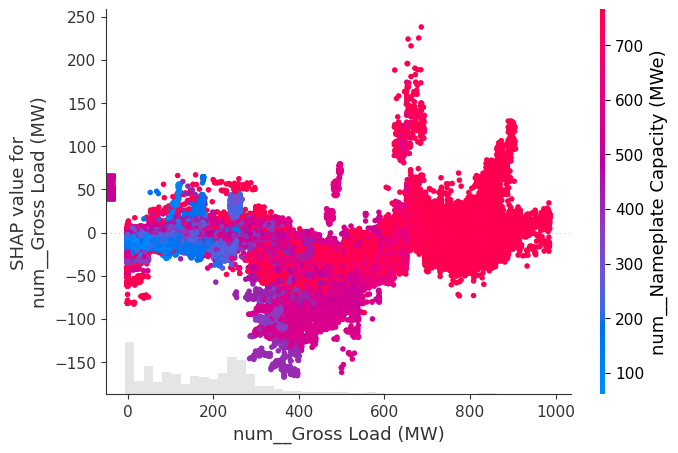

In [19]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Nameplate Capacity (MWe)"])

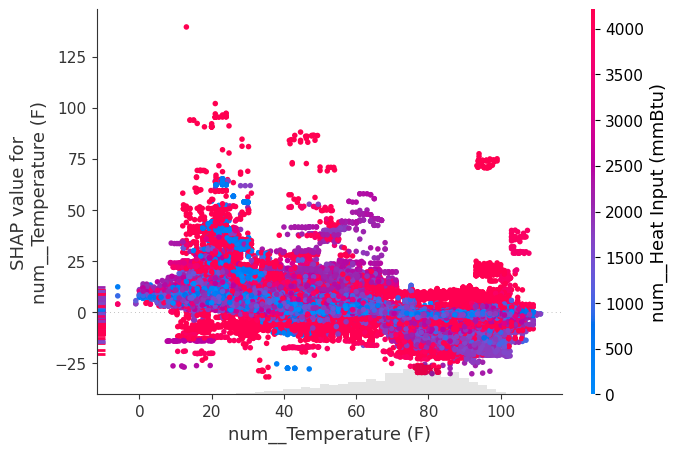

In [ ]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"num__Heat Input (mmBtu)"])

# effect is less visible compared to NY

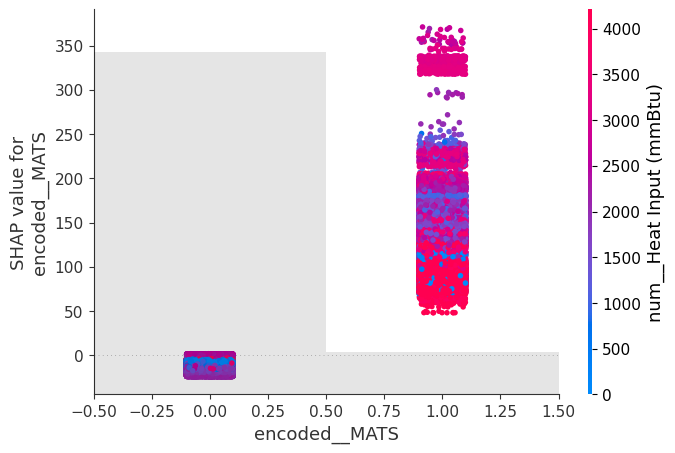

In [ ]:
shap.plots.scatter(shap_values[:, "encoded__MATS"], color=shap_values[:, "num__Heat Input (mmBtu)"])

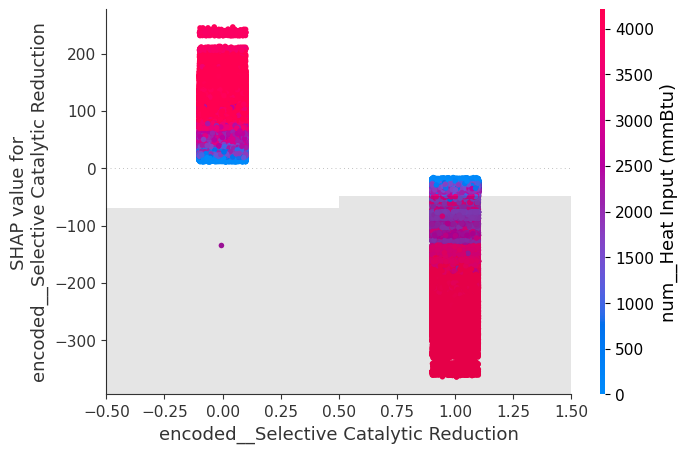

In [ ]:
# interaction between SCR and Heat Input is straightforward
# If SCR is present and heat input is high, then effect towards emissions is highly negative (negative SHAP value)
# If SCR is not present and heat input is high, then effect towards emissions is extremely large 

shap.plots.scatter(shap_values[:,"encoded__Selective Catalytic Reduction"], color=shap_values[:,"num__Heat Input (mmBtu)"])

<h5>SHAP Interaction Values</h5>

- calculate 2nd-order SHAP interaction values for the model without lags using a 100,000 row sample to limit computational strain
- to validate, we aggregate these interaction values globally and compare with the SHAP values computed on the full X_test earlier
- explore dependence plots (scatter plots of interaction values)

In [ ]:
X_test_sample = X_test.sample(n=100000, random_state=42)

interaction_values_shap = explainer.shap_interaction_values(X_test_sample)

# took 70 mins

In [24]:
joblib.dump(interaction_values_shap, "TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/interaction_values_shap_xgb_default_model_tx_no_lags_no_unmeasured_with_temps.pkl")

['TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/interaction_values_shap_xgb_default_model_tx_no_lags_no_unmeasured_with_temps.pkl']

In [ ]:
interaction_values_shap = joblib.load("TX/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/interaction_values_shap_xgb_default_model_tx_no_lags_no_unmeasured_with_temps.pkl")

In [ ]:
# first we explore how consistent the SI are with SV

In [ ]:
interaction_values_shap.shape

# interaction_values_shap[i][j][j] gives the main effect of feature j for sample i
# interaction_values_shap[i][j][k] gives the interaction effect of feature j and k for sample i (this is symmetric)

(100000, 131, 131)

In [36]:
# compute total difference in global shap values between the two calculations

global_shap_vals_interact = np.zeros(interaction_values_shap.shape[1])
global_shap_vals_original = np.zeros(interaction_values_shap.shape[1])

# 
for f in range(interaction_values_shap.shape[1]):
    # Sum interaction values for feature f across all interactions (axis=2),
    # then take absolute value and average over samples (axis=0)
    
    global_shap_vals_interact[f] = np.abs(interaction_values_shap[:, f, :].sum(axis=1)).mean()


    # Mean absolute shap value for feature f from original shap values
    global_shap_vals_original[f] = np.abs(shap_values.values[:, f]).mean()

Mean absolute difference: 0.009382
Max absolute difference: 0.312210
Min absolute difference: 0.000000


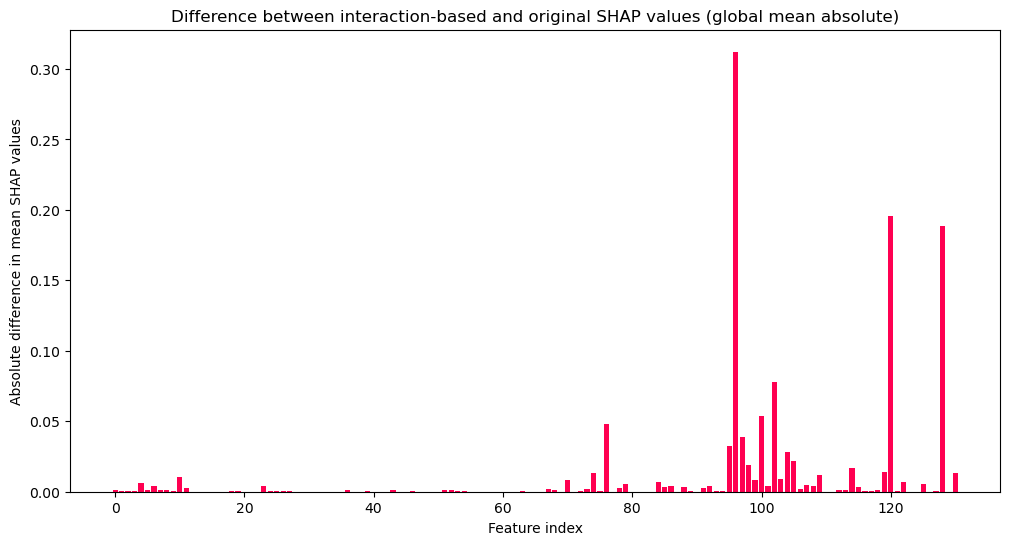

In [40]:
# Compute the absolute differences between the two sets
differences = np.abs(global_shap_vals_interact - global_shap_vals_original)

# Summary stats
print(f"Mean absolute difference: {differences.mean():.6f}")
print(f"Max absolute difference: {differences.max():.6f}")
print(f"Min absolute difference: {differences.min():.6f}")

plt.figure(figsize=(12, 6))
plt.bar(range(len(differences)), differences, color='#FF0051')
plt.xlabel('Feature index')
plt.ylabel('Absolute difference in mean SHAP values')
plt.title('Difference between interaction-based and original SHAP values (global mean absolute)')
plt.show()

# very small differences, maximum is 0.05

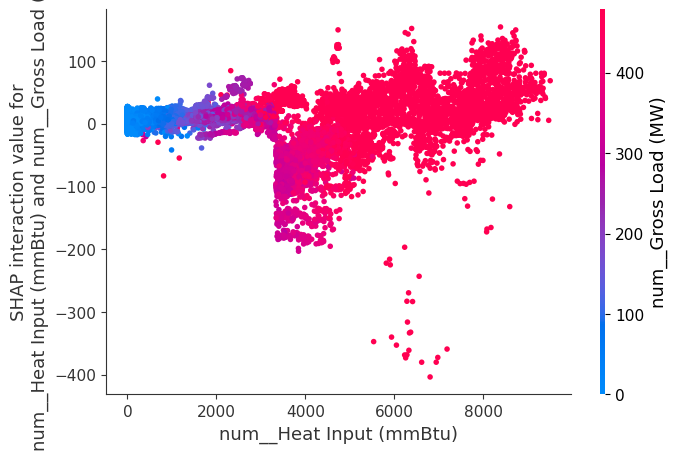

In [44]:
shap.dependence_plot(("num__Heat Input (mmBtu)", "num__Gross Load (MW)"), interaction_values_shap, X_test_sample, show=True)

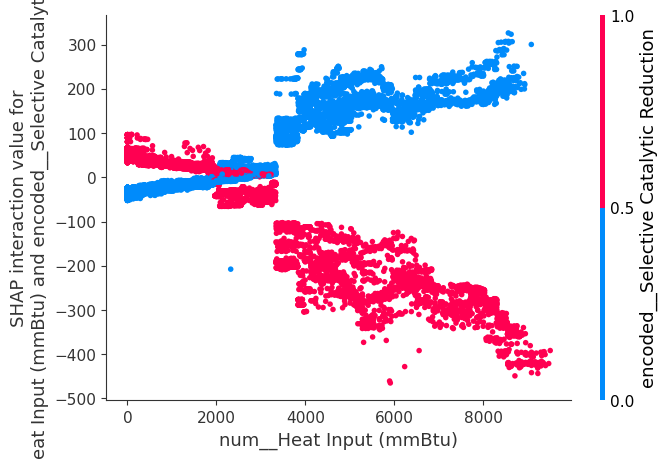

In [45]:
shap.dependence_plot(("num__Heat Input (mmBtu)", "encoded__Selective Catalytic Reduction"), interaction_values_shap, X_test_sample, show=True)

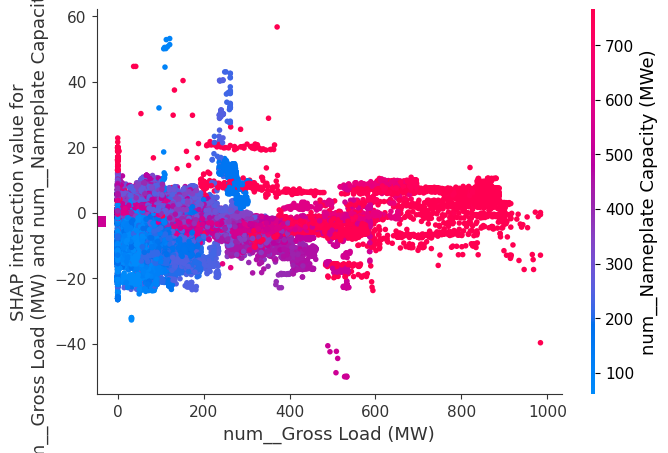

In [46]:
shap.dependence_plot(("num__Gross Load (MW)", "num__Nameplate Capacity (MWe)"), interaction_values_shap, X_test_sample, show=True)